<a href="https://colab.research.google.com/github/packageIncoming/MAT422/blob/main/MAT422_Section_3_5_3_6_KMeans_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Sections 3.5 and 3.6: K-means and Support Vector Machines

**Topics:** K-means, Support vector machine

> Student note: This Colab badge is required for submission. Create or edit the notebook in Google Colab, then save it directly to GitHub so the badge/icon remains available for grading and reruns.

Mert Isik MAT422 Fall 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=4, suppress=True)


## K-means

This section gives one compact Python demonstration of **K-means**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


Cluster centers:
[[ 5.1564 -9.2426]
 [-5.7803  5.6874]
 [ 6.3064  2.0914]
 [-3.3102 -3.1909]]
Inertia: 1816.920531789919


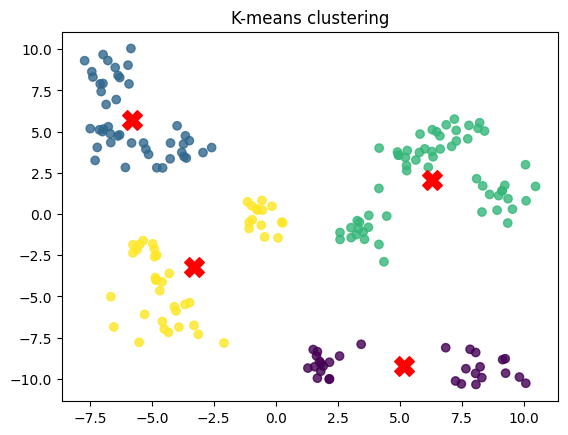

In [7]:
X, true_labels = make_blobs(n_samples=180, centers=12, cluster_std=0.7, random_state=422)
kmeans = KMeans(n_clusters=4, n_init=10, random_state=422)
cluster_labels = kmeans.fit_predict(X)

print("Cluster centers:")
print(kmeans.cluster_centers_)
print("Inertia:", kmeans.inertia_)

plt.scatter(X[:,0], X[:,1], c=cluster_labels, cmap="viridis", alpha=0.8)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], marker="X", s=200, color="red")
plt.title("K-means clustering")
plt.show()


K-means clustering is a way to find k groupings within a dataset without exactly knowing what the groups are. It involves attempting to find the center by placing points randomly, assigning points to their closest markers, and correcting the center of the points based on what is closest. The inertia represents the distance squared between every point to its assigned center.

## Support vector machine

This section gives one compact Python demonstration of **Support vector machine**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


Training accuracy: 0.8875
Number of support vectors: [36 35]


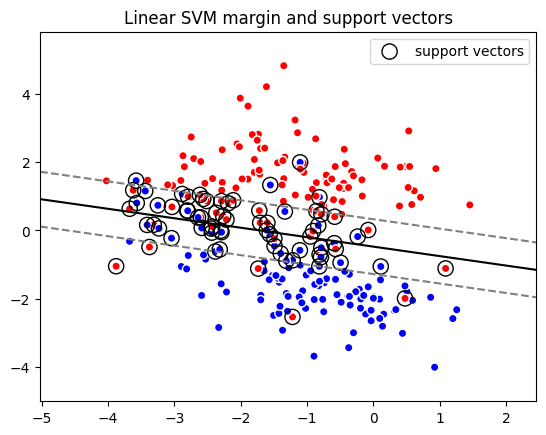

In [11]:
Xc, yc = make_classification(n_samples=240, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, class_sep=1.3, random_state=422)
svm = SVC(kernel="linear", C=100)
svm.fit(Xc, yc)
pred = svm.predict(Xc)

print("Training accuracy:", accuracy_score(yc, pred))
print("Number of support vectors:", svm.n_support_)

xx, yy = np.meshgrid(np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 150),
                     np.linspace(Xc[:,1].min()-1, Xc[:,1].max()+1, 150))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
plt.scatter(Xc[:,0], Xc[:,1], c=yc, cmap="bwr", edgecolor="white")
plt.scatter(svm.support_vectors_[:,0], svm.support_vectors_[:,1], s=120, facecolors="none", edgecolors="black", label="support vectors")
plt.title("Linear SVM margin and support vectors")
plt.legend()
plt.show()


SVM attempts to split the data, with the goal of having as much buffer space on either side of the line as possible. Support vectors are the datapoints closest to the line that affect the said buffer size.

## Reflection and Submission Checklist

- I explained each concept in words before or after the code.
- I verified important claims numerically or visually.
- I changed or extended at least one example so the notebook reflects my own work.
- I ran the notebook from top to bottom without errors.
- I saved the notebook from Google Colab directly to GitHub, following the course instructions.
